In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import csv
from tqdm import tqdm
import chemparse
import json
import math
from glob import glob
import pickle

Unable to revert mtime: /Library/Fonts
Fontconfig warning: ignoring UTF-8: not a valid region tag


In [2]:
# Matplotlib defaults

font = {"family" : "normal",
    "size" : 22}

for key, value in font.items():
    plt.rcParams.update({"font." + key : value})

achiral_color = "#FFC012"
chiral_color = "#34CCFF"
luca_color = "indigo"

In [3]:
def getFormulaDict(f):
    
    return chemparse.parse_formula(f)

def find_domain(formula, domain_cpds):
    if formula in domain_cpds:
        return 1
    else:
        return 0
    
def getNumHeavyAtoms(f):
    """ Find the number of heavy atoms (non-Hs)

    Args:
        f (dict): dictionary of elements & atom counts

    Returns:
        int: number of non-H atoms
    """
    #Remove Hs
    if "H" in f:
        f.pop("H")

    #Count number of other atoms (heavy atoms are non-Hs)
    return sum(f.values())

In [4]:
fp = "Data/chiral_molweight_formula_labels.csv"
df = pd.read_csv(fp)
df["formula_dict"] = df["Formula"].apply(getFormulaDict)
df["Heavy_Atoms"] = df["formula_dict"].apply(getNumHeavyAtoms)

for domain in ["archaea", "bacteria", "metagenome", "eukarya", "all"]:
    print("---- Analyzing", domain, "----")
    if domain == "all":
        files = glob("Data/*_occurance.csv")
        domain_df = pd.merge(
            pd.read_csv(files.pop()),
            pd.read_csv(files.pop()),
            how="outer"
        )
        while files:
            domain_df = pd.merge(
                domain_df, 
                pd.read_csv(files.pop()), 
                how='outer'
            )

        domain_cpds = list(domain_df["Cpd"])

    else:
        domain_df = pd.read_csv("Data/" + domain + "_occurance.csv")
        domain_cpds = list(domain_df["Cpd"])

    df[domain] = df["C"].apply(find_domain, args=(domain_cpds,))


FileNotFoundError: [Errno 2] No such file or directory: 'Data/chiral_molweight_formula_labels.csv'

In [5]:
def process_expansion(fpath):
  with open(fpath) as f:
    #load file and create a dataframe called "generations"
    datajson = json.load(f)
    generations = pd.DataFrame(datajson["generations"])
    generations = generations.transpose()
    generations.index = generations.index.astype(int)
    generations = generations.sort_index()
    original_columns = generations.columns

    #Add n columns
    for col in original_columns:
        generations["n_"+col] = generations[col].str.len() 

    return generations

In [6]:
# Read in chiral labels of KEGG compounds. Contains KEGG cpd ID, SMILES string, & number of chiral centers
fp = "Data/chiral_labels.csv"
chiral_df = pd.read_csv(fp)
chiral_df.head()

#make compound: num chiral centers dictionary
cpd_ccs = dict(zip(chiral_df.Cpd, chiral_df.Chiral_Centers))

In [7]:
### Find percentages of chiral/achiral cpds at each generation
fpath = "Data/primordial.dat0.json"
primordial_generations = process_expansion(fpath)
print(primordial_generations.columns)

#Percentage of chiral/achiralcompounds at each expansion step
percent_chiral = []
percent_achiral = []

step = 0

for index, row in primordial_generations.iterrows():
    chiral_count = 0
    achiral_count = 0
    if step == 3: #First chiral compounds
        print("Step 3: ", end="")
        print("Total Reactions:", len(row["reactions_cumulative"]), end=" ")
        print("Total Compounds:", len(row["compounds_cumulative"]))

    if step == 28: #Last addition to LUCA
        print("Step 28: ", end="")
        print("Total Reactions:", len(row["reactions_cumulative"]), end=" ")
        print("Total Compounds:", len(row["compounds_cumulative"]))

    for cpd in row["compounds_new"]:
        try:
            if cpd_ccs[cpd] == 0:
                achiral_count += 1
            else:
                if step == 3:
                    print(cpd)
                chiral_count += 1
        except:
            pass
    
    if len(row["compounds_new"]) > 0:
        percent_chiral.append(chiral_count / float(len(row["compounds_new"])))
        percent_achiral.append(achiral_count / float(len(row["compounds_new"])))
    else:
        percent_chiral.append(0)
        percent_chiral.append(0)

    step += 1
    

print(percent_chiral)
print(percent_achiral)

Index(['targets_new', 'targets_cumulative', 'compounds_cumulative',
       'reactions_cumulative', 'compounds_new', 'reactions_new',
       'n_targets_new', 'n_targets_cumulative', 'n_compounds_cumulative',
       'n_reactions_cumulative', 'n_compounds_new', 'n_reactions_new'],
      dtype='object')
Step 3: Total Reactions: 74 Total Compounds: 48
C16482
Step 28: Total Reactions: 6519 Total Compounds: 4543
[0.0, 0.0, 0.0, 0.06666666666666667, 0.08695652173913043, 0.0967741935483871, 0.28125, 0.19444444444444445, 0.41379310344827586, 0.5294117647058824, 0.4700854700854701, 0.5565217391304348, 0.5645161290322581, 0.6588235294117647, 0.7120622568093385, 0.6127819548872181, 0.6651376146788991, 0.5056179775280899, 0.5467836257309941, 0.56875, 0.5201612903225806, 0.5763546798029556, 0.5210526315789473, 0.6070287539936102, 0.5844594594594594, 0.6846153846153846, 0.6780487804878049, 0.7682119205298014, 0.7523809523809524, 0.7571428571428571, 0.7142857142857143, 0.75, 0.75, 0.7560975609756098, 0

In [8]:
### Find the average number of heavy atoms of new chiral/achiral cpds at each generation

achiral_avgHeavyAtoms = []
achiral_stdHeavyAtoms = []
chiral_avgHeavyAtoms = []
chiral_stdHeavyAtoms = []
all_avgHeavyAtoms = []
all_stdHeavyAtoms = []

for _, row in primordial_generations.iterrows():
    achiral_cpds = []
    chiral_cpds = []

    for cpd in row["compounds_cumulative"]:
        #Find chiral/achiral cpds in each row
        try:
            if cpd_ccs[cpd] == 0:
                achiral_cpds.append(cpd)
            else:
                chiral_cpds.append(cpd)
        except:
            pass

    #Find avg heavy atom count of these atoms

    achiral_avgHeavyAtoms.append(np.mean(df[df["C"].isin(achiral_cpds)]["Heavy_Atoms"]))
    achiral_stdHeavyAtoms.append(np.std(df[df["C"].isin(achiral_cpds)]["Heavy_Atoms"]))

    chiral_avgHeavyAtoms.append(np.mean(df[df["C"].isin(chiral_cpds)]["Heavy_Atoms"]))    
    chiral_stdHeavyAtoms.append(np.std(df[df["C"].isin(chiral_cpds)]["Heavy_Atoms"]))

    all_avgHeavyAtoms.append(np.mean(df[df["C"].isin(list(row["compounds_cumulative"]))]["Heavy_Atoms"]))
    all_stdHeavyAtoms.append(np.std(df[df["C"].isin(list(row["compounds_cumulative"]))]["Heavy_Atoms"]))



print(achiral_avgHeavyAtoms)
print(chiral_avgHeavyAtoms)
print(all_avgHeavyAtoms)
    

[2.5, 4.777777777777778, 4.90625, 5.391304347826087, 6.611940298507463, 7.557894736842106, 7.889830508474576, 8.267123287671232, 8.556122448979592, 8.829365079365079, 9.105095541401274, 9.273972602739725, 9.422434367541767, 9.545263157894738, 9.778793418647167, 10.236476043276662, 10.80586592178771, 11.43144208037825, 11.763527054108216, 12.116197183098592, 12.45171588188348, 12.593258426966292, 12.680925666199158, 13.0, 13.411411411411411, 13.70217640320733, 13.928256070640177, 14.035752979414951, 14.122863247863247, 14.183262711864407, 14.213459516298633, 14.243342036553525, 14.23908523908524, 14.230093071354705, 14.233109850438371, 14.24704065877509, 14.24704065877509, 14.24704065877509, 14.24704065877509, 14.24704065877509, 14.251543209876543, 14.251543209876543, 14.251543209876543, 14.251543209876543, 14.262589928057555, 14.268104776579353]
[nan, nan, nan, 12.0, 11.0, 10.833333333333334, 11.466666666666667, 11.181818181818182, 10.89655172413793, 12.181818181818182, 12.818181818181

Text(0, 0.5, 'Avg Heavy Atom Count (cumulative cpds)')

findfont: Font family ['normal'] not found. Falling back to DejaVu Sans.
findfont: Font family ['normal'] not found. Falling back to DejaVu Sans.


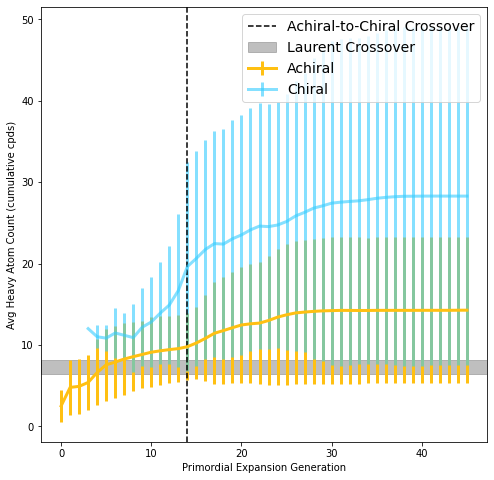

In [9]:
## Plot percentages of chiral/achiral of primordial expansion
plt.figure(figsize=(8,8))

plt.errorbar(x=np.arange(0, len(all_avgHeavyAtoms), 1), y=achiral_avgHeavyAtoms, yerr=achiral_stdHeavyAtoms,
    linewidth=3, label="Achiral", color=achiral_color)

plt.errorbar(x=np.arange(0, len(all_avgHeavyAtoms), 1), y=chiral_avgHeavyAtoms, yerr=chiral_stdHeavyAtoms,
    linewidth=3, label="Chiral", alpha=0.6, color=chiral_color)

# plt.errorbar(x=np.arange(0, len(all_avgHeavyAtoms), 1), y=all_avgHeavyAtoms, yerr=all_stdHeavyAtoms,
#     linewidth=3, label="All Compounds", alpha=0.6)

plt.axvline(x=14, color="k", linestyle="--", label="Achiral-to-Chiral Crossover")
plt.axhspan(6.4, 8.1, alpha=0.5, color='grey', label="Laurent Crossover")


plt.legend(prop={"size":14})

plt.xlabel("Primordial Expansion Generation")
plt.ylabel("Avg Heavy Atom Count (cumulative cpds)")

In [9]:
#Number of chiral/achiral compounds at each expansion step
num_chiral = []
num_achiral = []

for index, row in primordial_generations.iterrows():
  chiral_count = 0
  achiral_count = 0
  for cpd in row["compounds_new"]:
    try:
      if cpd_ccs[cpd] == 0:
        achiral_count += 1
      else:
        chiral_count += 1
    except:
      pass
  num_chiral.append(chiral_count)
  num_achiral.append(achiral_count)

print(num_chiral)

[0, 0, 0, 1, 2, 3, 9, 7, 36, 63, 55, 64, 70, 112, 183, 163, 145, 135, 187, 182, 129, 117, 99, 190, 173, 178, 139, 116, 79, 53, 35, 39, 27, 31, 26, 16, 7, 5, 4, 4, 2, 5, 4, 1, 0, 0]


In [10]:
# Calculate percentage of luca

#Read in LUCA compounds
fpath = "Data/Luca_ec_compound_unique_list_clean.json"
with open(fpath) as f:
  data = json.load(f)
luca_cpds = data["Luca"]

percent_luca = []
for index, row in primordial_generations.iterrows():
  luca_count = 0
  for cpd in row["compounds_cumulative"]:
    if cpd in luca_cpds:
      luca_count += 1
  percent_luca.append(float(luca_count) / len(luca_cpds))

percent_luca = np.array(percent_luca)*100
print(percent_luca)

[ 1.14155251  1.82648402  2.05479452  2.05479452  2.73972603  3.19634703
  3.65296804  6.84931507 12.10045662 17.35159817 22.14611872 27.39726027
 31.50684932 38.58447489 45.43378995 51.59817352 54.56621005 58.44748858
 61.64383562 64.84018265 66.43835616 68.03652968 69.6347032  71.68949772
 72.37442922 72.60273973 73.05936073 73.51598174 73.74429224 73.97260274
 73.97260274 73.97260274 73.97260274 73.97260274 73.97260274 73.97260274
 73.97260274 73.97260274 73.97260274 73.97260274 73.97260274 73.97260274
 73.97260274 73.97260274 73.97260274 73.97260274]


In [11]:
cum_num_chiral = np.cumsum(num_chiral)
cum_num_achiral = np.cumsum(num_achiral)

In [ ]:
# crossover plot (just chiral & achiral) with % luca at each step

plt.figure(figsize=(10,10))
plt.rcParams.update({'font.size': 22, 'xtick.labelsize':'large',
         'ytick.labelsize':'large'})

fig, ax = plt.subplots(figsize=(10,10))
ax2 = ax.twinx()

#Regular crossover plot
ax.plot(cum_num_chiral, color=chiral_color, marker="o", linewidth=4, markersize=10,
         label="Chiral Compounds")
ax.plot(cum_num_achiral,  color=achiral_color, marker="o", linewidth=4, markersize=10,
         label="Achiral Compounds")

#Histogram of LUCA percentage
ax2.set_ylim([0,100])
ax2.bar(np.arange(0,len(percent_luca),1), percent_luca, alpha=0.25, color=luca_color,
        label="LUCA Percentage")

#Combine legends
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines + lines2, labels + labels2, facecolor="white", prop={"size": 18})

# ax.legend(facecolor="white", prop={"size": 18})
# ax2.legend(facecolor="white")
ax.set_xlabel("Generations", fontsize=22)
ax.set_ylabel("Compounds", fontsize=22)
ax2.set_ylabel("Percentage", fontsize=22)

In [12]:
def get_percentage(cum_chiral, cum_achiral):
    """ Get percentage chiral at a specific location

    Args:
        cum_chiral (list): cumulative sum of chiral compounds over generations
        cum_achiral (list): cumulative sum of achiral compounds over generations
    """
    chiral_percent = []
    for i in range(len(cum_chiral)):
        chiral_percent.append( float(cum_chiral[i]) / (cum_chiral[i] + cum_achiral[i]) )

    return chiral_percent
    

In [16]:
### Primordial expansion percent chiral
primordial_cumChiral = np.cumsum(num_chiral)
primordial_cumAchiral = np.cumsum(num_achiral)

primordial_chiralPercent = get_percentage(primordial_cumChiral, primordial_cumAchiral)

print(primordial_chiralPercent)

[0.0, 0.0, 0.0, 0.02127659574468085, 0.04285714285714286, 0.0594059405940594, 0.11278195488721804, 0.13095238095238096, 0.2283464566929134, 0.32439678284182305, 0.35918367346938773, 0.39669421487603307, 0.4252400548696845, 0.47045707915273133, 0.5251736111111112, 0.542756183745583, 0.5604665438919583, 0.5533262935586061, 0.5530676220331393, 0.5550332941637289, 0.5523401214719542, 0.5547031354236157, 0.5526976160602258, 0.5578736781937697, 0.5606860158311345, 0.5687824154112127, 0.5740479548660085, 0.5808356039963669, 0.5848303393213573, 0.5875928352992573, 0.588934514804409, 0.5907245137849968, 0.5919406150583245, 0.5933557611438184, 0.5949446417380405, 0.5957977948824631, 0.5963855421686747, 0.5968043162481843, 0.5971387103462575, 0.5974725502382432, 0.5975155279503106, 0.5979317476732161, 0.5982641041537508, 0.5983471074380166, 0.5980999586947542, 0.5979764608713607]


In [13]:
#Get statistics from pickle files (from expansion_analysis.py)
achiral_achiral_sizes = pickle.load(file=open("Data/achiral_achiral_sizes.p", "rb"))
achiral_chiral_sizes = pickle.load(file=open("Data/achiral_chiral_sizes.p", "rb"))

chiral_achiral_sizes = pickle.load(file=open("Data/chiral_achiral_sizes.p", "rb"))
chiral_chiral_sizes = pickle.load(file=open("Data/chiral_chiral_sizes.p", "rb"))


In [14]:
achiral_chiralPercentage = []
chiral_chiralPercentage = []

for i in range(len(achiral_chiral_sizes)):
    achiral_chiralPercentage.append(get_percentage(np.cumsum(achiral_chiral_sizes[i]), np.cumsum(achiral_achiral_sizes[i])))

for i in range(len(chiral_chiral_sizes)):
    chiral_chiralPercentage.append(get_percentage(np.cumsum(chiral_chiral_sizes[i]), np.cumsum(chiral_achiral_sizes[i])))

print(achiral_chiralPercentage[0])

[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.02857142857142857, 0.05263157894736842, 0.05128205128205128, 0.05434782608695652, 0.13675213675213677, 0.2214765100671141, 0.26229508196721313, 0.25980392156862747, 0.2636363636363636, 0.2683982683982684, 0.2782258064516129, 0.31076923076923074, 0.3226600985221675, 0.3177966101694915, 0.3156934306569343, 0.345679012345679, 0.35618279569892475, 0.3593556381660471, 0.3614864864864865, 0.4111431316042267, 0.43976411120471776, 0.46248085758039814, 0.49375866851595007, 0.5133214920071048, 0.5330210772833723, 0.5389197776012709, 0.5422939068100359, 0.5471760797342192, 0.5483468496568933, 0.5499707773232028, 0.5539094650205761, 0.5650623885918004, 0.5679012345679012, 0.575046468401487, 0.5803470813612801, 0.5844385499557914, 0.5873015873015873, 0.5893968662803176, 0.5902023429179979, 0.5915136162127929, 0.592918499895244, 0.5939192003331945, 0.5950207468879668, 0.5957755228825844, 0.5961100765570039, 0.5964440769071738, 0.5964876033057851, 0.5969040247678019, 

/Users/johnmalloy/opt/miniconda3/envs/my-rdkit-env/lib/python3.7/site-packages/ipykernel_launcher.py:10: RuntimeWarning: invalid value encountered in true_divide
  # Remove the CWD from sys.path while we load stuff.


In [15]:
# print(combined_achiral_luca_percents)

achiral_avg_percentages_chiral = []
achiral_std_percentages_chiral = []

chiral_avg_percentages_chiral = []
chiral_std_percentages_chiral = []


for i in tqdm(range(100)): #100 steps is larger than any other expansion
    percentages = [] 
    for result in achiral_chiralPercentage:
        if len(result) > i:
            percentages.append(result[i])

    achiral_avg_percentages_chiral.append(np.mean(percentages))
    achiral_std_percentages_chiral.append(np.std(percentages))

    percentages = [] 
    for result in chiral_chiralPercentage:
        if len(result) > i:
            percentages.append(result[i])

    chiral_avg_percentages_chiral.append(np.mean(percentages))
    chiral_std_percentages_chiral.append(np.std(percentages))

print(chiral_avg_percentages_chiral)
print(chiral_std_percentages_chiral)

 62%|██████▏   | 62/100 [00:00<00:00, 613.22it/s]/Users/johnmalloy/opt/miniconda3/envs/my-rdkit-env/lib/python3.7/site-packages/numpy/core/fromnumeric.py:3441: RuntimeWarning: Mean of empty slice.
  out=out, **kwargs)
/Users/johnmalloy/opt/miniconda3/envs/my-rdkit-env/lib/python3.7/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/johnmalloy/opt/miniconda3/envs/my-rdkit-env/lib/python3.7/site-packages/numpy/core/_methods.py:263: RuntimeWarning: Degrees of freedom <= 0 for slice
  keepdims=keepdims, where=where)
/Users/johnmalloy/opt/miniconda3/envs/my-rdkit-env/lib/python3.7/site-packages/numpy/core/_methods.py:223: RuntimeWarning: invalid value encountered in true_divide
  subok=False)
/Users/johnmalloy/opt/miniconda3/envs/my-rdkit-env/lib/python3.7/site-packages/numpy/core/_methods.py:254: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
100%

[nan, 0.7780236118956286, 0.6856863728777924, 0.6079523593475042, 0.5472074343076272, 0.5056637172671706, 0.474724236769888, 0.45947166973485215, 0.45442417559956555, 0.45184449623906314, 0.4548454212763454, 0.4595730231687197, 0.4631541978546751, 0.46844626106984205, 0.47292734678670834, 0.4789298387494313, 0.48556273951214757, 0.4920165320848122, 0.4981864863929961, 0.5037218809895034, 0.5097597009025127, 0.5214508347990737, 0.5290693331330097, 0.5349508307475944, 0.5386537223708538, 0.5430267576732429, 0.5496036491548612, 0.5553342929122707, 0.5601562823332477, 0.5644685493385448, 0.5671998404929722, 0.5797013413688954, 0.5871595510408268, 0.589372279088371, 0.5909844789651598, 0.593337234026269, 0.5944470102097725, 0.5952949263414272, 0.5960232715695866, 0.5966014651848378, 0.5971590105683945, 0.597557640747484, 0.5979239943200901, 0.5982162266381402, 0.5984833703745958, 0.598703885631627, 0.5987760045737318, 0.5988357305693669, 0.5989826807976599, 0.5990819630175113, 0.59913042274

In [ ]:
plt.figure(figsize=(10,10))


#Chiral
plt.errorbar(x=np.arange(0, len(chiral_avg_percentages_chiral), 1), y=chiral_avg_percentages_chiral, 
             yerr=chiral_std_percentages_chiral, color=chiral_color, marker="o", linewidth=3, 
             markersize=10, label="Chiral Seed Sets")


# for p in chiral_chiralPercentage[0:10]:
#     plt.plot(p, color="lightcoral", marker="o", linewidth=1, markersize=2) #, alpha=0.1)

## Achiral
plt.errorbar(x=np.arange(0, len(achiral_avg_percentages_chiral), 1), y=achiral_avg_percentages_chiral, 
             yerr=achiral_std_percentages_chiral, color=achiral_color, marker="o", linewidth=3, 
             markersize=10, label="Achiral Seed Sets")

# for p in achiral_chiralPercentage[0:10]:
#     plt.plot(p, color="peru", marker="o", linewidth=1, markersize=2) #, alpha=0.1)


plt.axhline(y=0.5, color="k", linewidth=3, linestyle="--")

plt.legend()
plt.xlabel("Generation")
plt.ylabel("Percent Chiral")


### Full figure

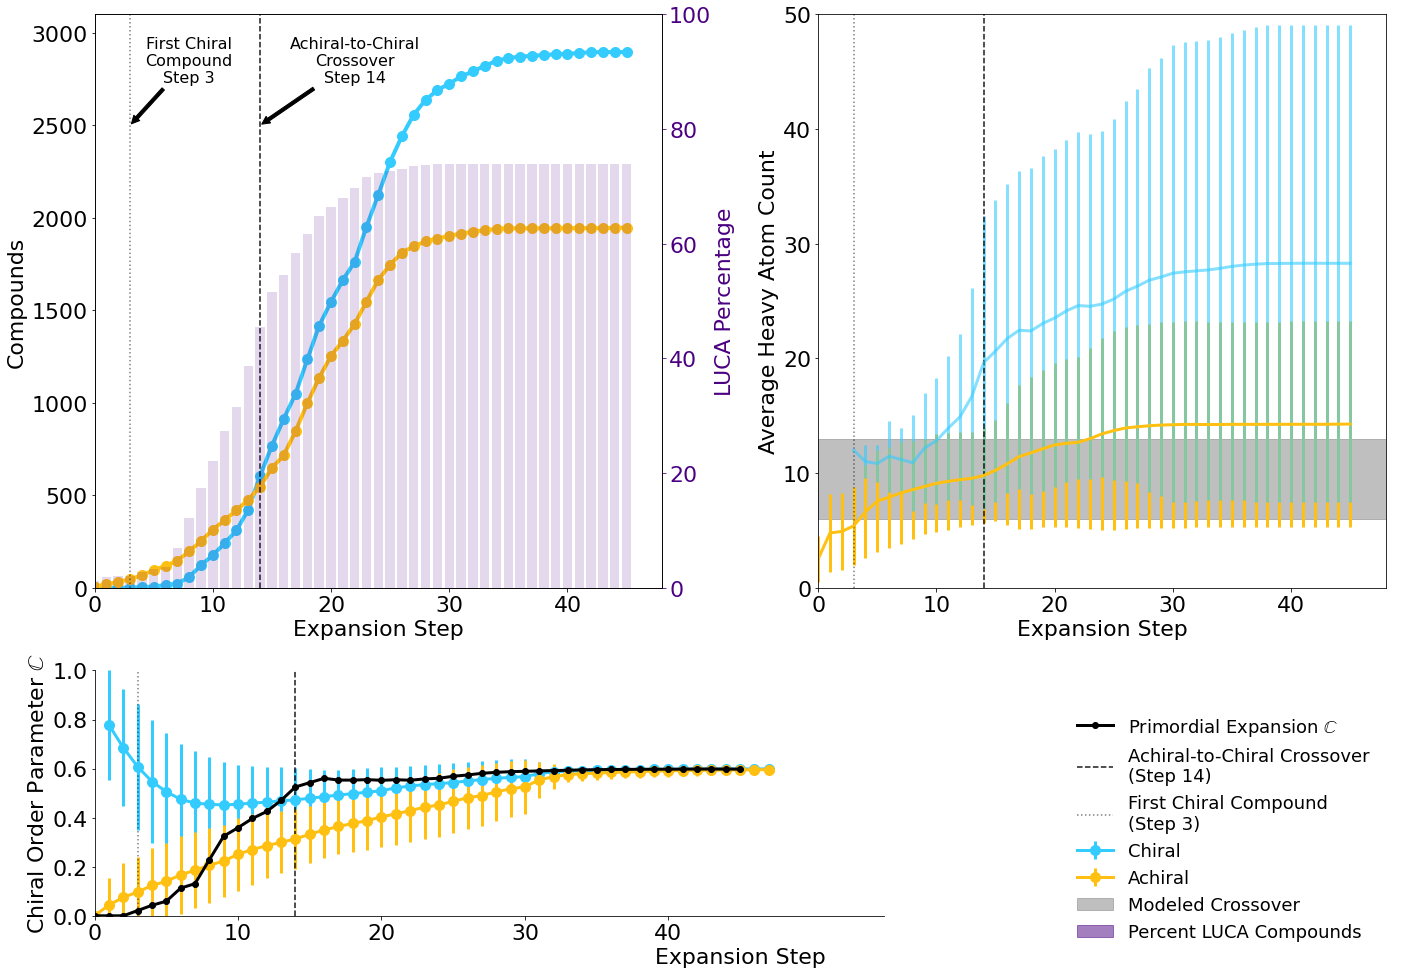

In [24]:
import matplotlib.gridspec as gridspec

plt.figure(figsize=(20,14))
gs = gridspec.GridSpec(6,2)


### Upper RIGHT plot
ax1 = plt.subplot(gs[0:4,1])
ax1.errorbar(x=np.arange(0, len(all_avgHeavyAtoms), 1), y=achiral_avgHeavyAtoms, yerr=achiral_stdHeavyAtoms,
    linewidth=3, label="Achiral", color=achiral_color)

ax1.errorbar(x=np.arange(0, len(all_avgHeavyAtoms), 1), y=chiral_avgHeavyAtoms, yerr=chiral_stdHeavyAtoms,
    linewidth=3, label="Chiral", alpha=0.6, color=chiral_color)

ax1.axvline(x=14, color="k", alpha=0.9, linestyle="--", label="Achiral-to-Chiral Crossover")
ax1.axhspan(6, 13, alpha=0.5, color='grey', label="Modeled Crossover")
ax1.axvline(x=3, color="k", alpha=0.5, linestyle=":", label="First Chiral Compound")

ax1.set_ylim([0,50])
ax1.set_xlim([0,48])

ax1.set_ylabel("Average Heavy Atom Count")
ax1.set_xlabel("Expansion Step")
#ax1.legend()


### Upper LEFT plot
ax2 = plt.subplot(gs[0:4,0])
ax2a = ax2.twinx()

#Regular crossover plot
ax2.plot(cum_num_chiral, color=chiral_color, marker="o", linewidth=4, markersize=10,
         label="Chiral Compounds")
ax2.plot(cum_num_achiral,  color=achiral_color, marker="o", linewidth=4, markersize=10,
         label="Achiral Compounds")
ax2.axvline(x=14, color="k", linestyle="--", alpha=0.9, label="Achiral-to-Chiral Crossover")
ax2.axvline(x=3, color="k", linestyle=":", alpha=0.5, label="First Chiral Compound")

ax2.annotate("Achiral-to-Chiral\nCrossover\nStep 14", xy=(14, 2500), xytext=(22,2850), color="k", 
             arrowprops={"arrowstyle": "simple", "color": "k"}, fontsize=16, ha='center', va='center', zorder=3)
ax2.annotate("First Chiral\nCompound\nStep 3", xy=(3, 2500), xytext=(8,2850), color="k", 
             arrowprops={"arrowstyle": "simple", "color": "k"}, fontsize=16, ha='center', va='center', zorder=3)


ax2.set_ylim([0, 3100])
ax2.set_xlim([0,48])

ax2.set_ylabel("Compounds")
ax2.set_xlabel("Expansion Step")


#Histogram of LUCA percentage
ax2a.set_ylim([0,100])
ax2a.bar(np.arange(0,len(percent_luca),1), percent_luca, alpha=0.15, color=luca_color,
        label="LUCA Percentage")

ax2a.set_ylabel("LUCA Percentage", color=luca_color)

#Set y-axis tick labels to luca color
ax2a.tick_params(colors=luca_color)

lines, labels = ax2.get_legend_handles_labels()
lines2, labels2 = ax2a.get_legend_handles_labels()
#ax2.legend(lines + lines2, labels + labels2, facecolor="white", prop={"size": 18})

ax3 = plt.subplot(gs[4:,:])

#Artifical x-axes - allows for legend space (full figure in SI)
chiral_avg_percentages_chiral = chiral_avg_percentages_chiral[0:48]
chiral_std_percentages_chiral = chiral_std_percentages_chiral[0:48]
achiral_avg_percentages_chiral = achiral_avg_percentages_chiral[0:48]
achiral_std_percentages_chiral = achiral_std_percentages_chiral[0:48]

#Chiral
ax3.errorbar(x=np.arange(0, len(chiral_avg_percentages_chiral), 1), y=chiral_avg_percentages_chiral, 
             yerr=chiral_std_percentages_chiral, color=chiral_color, marker="o", linewidth=3, 
             markersize=10, label="Chiral")

## Achiral
ax3.errorbar(x=np.arange(0, len(achiral_avg_percentages_chiral), 1), y=achiral_avg_percentages_chiral, 
             yerr=achiral_std_percentages_chiral, color=achiral_color, marker="o", linewidth=3, 
             markersize=10, label="Achiral")

## Primordial
ax3.plot(primordial_chiralPercent, "o-", color="k", linewidth=3, zorder=5, label="Primordial Expansion $\mathbb{C}$")

ax3.axvline(x=14, color="k", linestyle="--", alpha=0.9, label="Achiral-to-Chiral Crossover\n(Step 14)")
ax3.axvline(x=3, color="k", linestyle=":", alpha=0.5, label="First Chiral Compound\n(Step 3)")


ax3.set_ylim([0,1])
ax3.set_xlim([0,90])

#Remove 100 & 120 from xticks
ax3_xticks = ax3.xaxis.get_major_ticks()
ax3_xticks[-1].set_visible(False)
ax3_xticks[-2].set_visible(False)
ax3_xticks[-3].set_visible(False)
ax3_xticks[-4].set_visible(False)
ax3_xticks[-5].set_visible(False)

#Remove x-axis spine past 55
ax3.spines['bottom'].set_bounds(0, 55)

#Remove top & right ax3 borders to make legend more obviously connected to the rest of the plot
ax3.spines[['right', 'top']].set_visible(False)

ax3.set_xlabel("Expansion Step")
ax3.set_ylabel("Chiral Order Parameter $\mathbb{C}$")
lgd = ax3.legend(prop={"size": 18}, frameon=False, loc="upper right") # bbox_to_anchor=(1.05,0.60))

def add_patch(legend):
    from matplotlib.patches import Patch
    ax = legend.axes

    handles, labels = ax.get_legend_handles_labels()
    handles.append(Patch(facecolor='grey', edgecolor='grey', alpha=0.5))
    labels.append("Modeled Crossover")

    handles.append(Patch(facecolor=luca_color, edgecolor=luca_color, alpha=0.5))
    labels.append("Percent LUCA Compounds")

    legend._legend_box = None
    legend._init_legend_box(handles, labels)
    legend._set_loc(legend._loc)
    #legend.set_title(legend.get_title().get_text())

add_patch(lgd)

plt.tight_layout()

plt.savefig("fig2.svg", format="svg")


### Display specific networks.
USER MUST click "post to python" in the Netwulf chrome window each time it opens, once node positions stabilize!

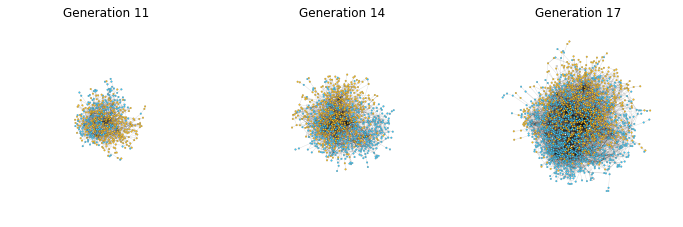

In [1]:
#Import packages - in case can't run cells above

# Must install: networkx, netwulf, simplejson>=3.0 (dependency for netwulf)
import networkx as nx
import netwulf as nw # install with pip install netwulf (github.com/benmaier/netwulf, cite doi.org/10.21105/joss.01425)

# If running this cell only, and not cells above it...
try:
    json
except NameError:
    import json
    import pandas as pd
    import matplotlib.pyplot as plt

# Import network expansions - pd.DataFrame: "node_generations"
node_generations = pd.DataFrame(json.load(open('Data/primordial.dat0.json','r'))['generations']).T.iloc[:,2:]
node_generations.index = node_generations.index.astype(int)
node_generations = node_generations.sort_index()

#Import chiralities, tag cpds for which chirality wasn't calculated - pd.Series: "is_chiral"
chiral_labels = pd.read_csv('Data/chiral_labels.csv', index_col='Cpd').drop(columns=['Index'])
is_chiral = pd.DataFrame(index=node_generations.iloc[-1]['compounds_cumulative']).combine_first(
    (chiral_labels['Chiral_Centers']>0).to_frame()).iloc[:,0]

reaction_pool = node_generations['reactions_cumulative'].iloc[-1] # identify the reactions we care about
node_roles = pd.DataFrame(json.load(open('Data/reaction_edges.json'))).loc[reaction_pool] # get details for those
compound_pool = node_roles.stack().explode().drop_duplicates().values # identify the compounds they imply
node_names = pd.read_csv('Data/compound_first_names_KEGGv110.0.csv.zip', index_col=0, header=0)['1'] # get cpd names, for labels
node_names = node_names.drop(node_names.index.difference(compound_pool)) # remove compounds not in networks (to save memory)

# Combine node data into a single DataFrame for fast assignment of attributes to nodes
node_data = pd.DataFrame(index=compound_pool, data={'is_chiral':is_chiral, 'name': node_names})
node_data['is_chiral_color'] = (node_data['is_chiral'].map({True: '#34CCFF', False: '#FFC012'}).fillna("#FFFFFF"))

# Generate and diagram networks
edges = node_roles.explode('substrates').explode('products') # All possible edges from substrate to product
fig, ax = plt.subplots(1,3, figsize=(12,5))
n = 0
gen_delta = 3
for generation in [14-gen_delta, 14, 14+gen_delta]:
    gen_edges = edges.loc[node_generations.loc[generation-1, 'reactions_cumulative']].drop_duplicates()
    G_uni = nx.from_pandas_edgelist(gen_edges, source='substrates', target='products', create_using=nx.Graph()) # create graph
    nx.set_node_attributes(G_uni, values = node_data.loc[list(G_uni.nodes), 'is_chiral_color'].to_dict(), name='group') #customized for netwulf
    stylized_network, config = nw.visualize(G_uni, config={'node_label_color': '#fefefe', 'node_size': 8, 'node_gravity': 0.15, 
                                'link_alpha': 0.15, 'link_color': '#000000', 'zoom': 0.68, 'node_charge': -53})
    nw.draw_netwulf(stylized_network, fig=fig, ax=ax[n]) # USER: click "post to python" in the netwulf window!
    n=n+1
ax[0].set_title('Generation 11')
ax[1].set_title('Generation 14')
ax[2].set_title('Generation 17')
plt.savefig('fig2_networks.svg', format='svg', dpi=300, facecolor='w')